# Efek Campaign Voucher: Difference-in-Differences — Observasional

Retailer yang memilih siapa yang dikirimi campaign bukan undian acak — tidak ada angka di notebook ini yang berdiri sebagai klaim kausal. Semua estimasi berlabel **`observasional — di bawah asumsi unconfoundedness`**, dan pekerjaan utamanya adalah menguji seberapa jauh asumsi itu bertahan: parallel pre-trend, overlap propensity, covariate balance.

Dua hal yang perlu diketahui di depan. Pertama, pembobotan memakai **overlap weights** — bobot terbatas pada [0,1] sehingga tidak perlu trim, balance tercapai untuk semua campaign, dan estimandnya adalah efek pada populasi overlap: member yang berada di margin targeting, justru yang paling relevan untuk keputusan menambah/mengurangi target list. Kedua, kisahnya: dari 20 campaign yang layak diperkirakan, **17 lolos semua gate diagnostik**; backbone 13 dan 18 menunjukkan lift mingguan +22,9% dan +24,4% (signifikan), sementara campaign 8 adalah peringatan yang berguna — estimasi signifikannya (+12,9%) **gagal uji placebo** dan karenanya ditandai, bukan dirayakan.

## 0. Setup

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.did import build_campaign_results
from src.features import PROCESSED_DIR, save_parquet

panel = pd.read_parquet(PROCESSED_DIR / "hh_week.parquet")
timeline = pd.read_parquet(PROCESSED_DIR / "campaign_timeline.parquet")
hh_campaign = pd.read_parquet(PROCESSED_DIR / "hh_campaign.parquet")
results, events = build_campaign_results(timeline, hh_campaign, panel)
save_parquet(results, PROCESSED_DIR / "campaign_did_results.parquet")
save_parquet(events, PROCESSED_DIR / "campaign_event_study.parquet")
est = results[results["estimated"]].copy()
print(f"{len(results)} campaign | {len(est)} diperkirakan | {len(events):,} baris event study")

30 campaign | 20 diperkirakan | 574 baris event study


## 1. Siapa dibandingkan dengan siapa

Untuk tiap campaign, treated dibandingkan dengan household yang tidak ditarget campaign itu **dan** tidak sedang menerima campaign lain yang window-nya beririsan. Baseline spend diambil dari 8 minggu sebelum campaign; efek diukur pada rata-rata spend mingguan selama window. Lima fitur pre-window (spend, frekuensi aktif, ketergantungan promo, ragam kategori, recency) masuk ke propensity score; bobot overlap menyeimbangkan kedua kelompok pada fitur-fitur itu tanpa membuang siapa pun dari sampel.

In [2]:
cols = ["campaign_id", "type", "n_weeks_window", "n_treated_analysis", "n_control_analysis", "ps_outside_trim_share"]
view = est[cols].copy().round(3)
view["n_control_analysis"] = view["n_control_analysis"].astype(int)
view  # n_analysis = seluruh populasi (overlap weights tidak mem-trim)

,campaign_id,type,n_weeks_window,n_treated_analysis,n_control_analysis,ps_outside_trim_share
4,5,B,5,166.0,2052,0.608
6,7,B,5,198.0,1384,0.590
7,8,A,7,1076.0,1359,0.125
8,9,B,5,176.0,1365,0.508
9,10,B,5,123.0,1951,0.693
10,11,B,7,214.0,1377,0.608
11,12,B,5,170.0,1377,0.646
12,13,A,7,1077.0,1374,0.107
13,14,C,10,224.0,1150,0.552
15,16,B,5,188.0,1308,0.611


## 2. Balance — dan kenapa bobot diganti

Sebelumnya dipakai ATT-IPW dengan trim propensity [0,05; 0,95]. Pada campaign menengah (treated 100–350 dari ±2.500) aturan itu membuang **median 58% sampel** — kebanyakan kontrol memang punya propensity di bawah 0,05 — dan tetap menyisakan imbalance (hanya 4 dari 20 lolos SMD < 0,1; sensitivity trim alternatif tidak memperbaiki). Bobot overlap menyelesaikan keduanya sekaligus: **20 dari 20 campaign lolos balance** (SMD maksimum 0,084) dengan sampel penuh. Estimasi ATT-IPW tetap dilaporkan sebagai kolom sensitivity — untuk backbone keduanya sepakat (contoh campaign 18: $5,84 overlap vs $6,29 IPW).

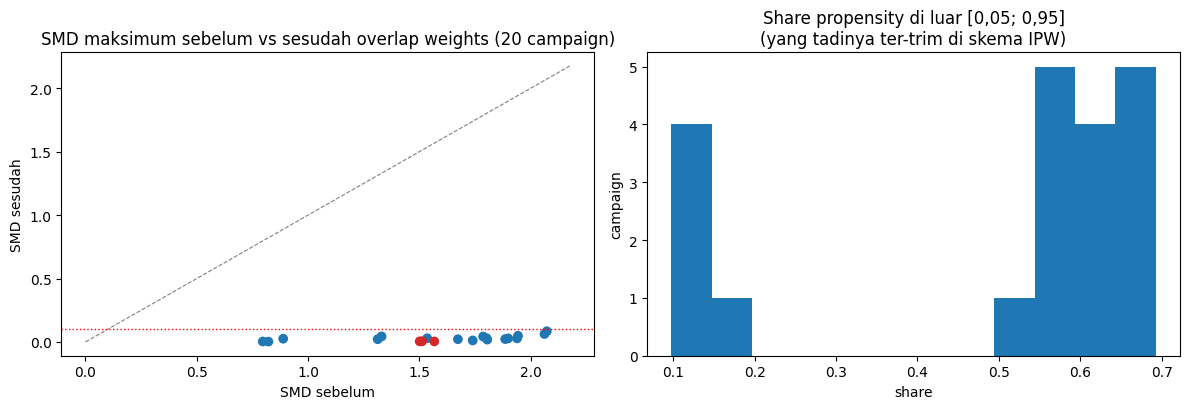

lolos SMD<0,1: 20 / 20 | SMD max: 0.084


In [3]:
bb_mask = est["campaign_id"].isin((8, 13, 18))
colors = np.where(bb_mask, "#d62728", "#1f77b4")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(est["smd_max_before"], est["smd_max_after"], c=colors)
lim = est["smd_max_before"].max() * 1.05
axes[0].plot([0, lim], [0, lim], color="gray", lw=0.8, ls="--")
axes[0].axhline(0.1, color="red", ls=":", lw=1)
axes[0].set(title="SMD maksimum sebelum vs sesudah overlap weights (20 campaign)", xlabel="SMD sebelum", ylabel="SMD sesudah")
axes[1].hist(est["ps_outside_trim_share"], bins=12, color="#1f77b4")
axes[1].set(title="Share propensity di luar [0,05; 0,95]\n(yang tadinya ter-trim di skema IPW)", xlabel="share", ylabel="campaign")
plt.tight_layout()
plt.show()
print("lolos SMD<0,1:", int((est['smd_max_after'] < 0.1).sum()), "/ 20 | SMD max:", round(float(est['smd_max_after'].max()), 3))

## 3. Event study — dua backbone yang sehat, satu yang tidak

Spend mingguan berbobot treated vs kontrol di sekitar awal campaign (minggu 0). Campaign 13 dan 18: garis bergerak sejajar sebelum minggu 0 lalu berpisah — persis pola yang DiD asumsikan, dan placebo formalnya lolos. Campaign 8 berbeda: pre-period-nya **tidak sejajar** dan CI placebo meng-exclude nol — estimasinya signifikan secara aritmetika tapi asumsi identifikasinya goyah, maka ditandai `tidak reliable — pre-trend`.

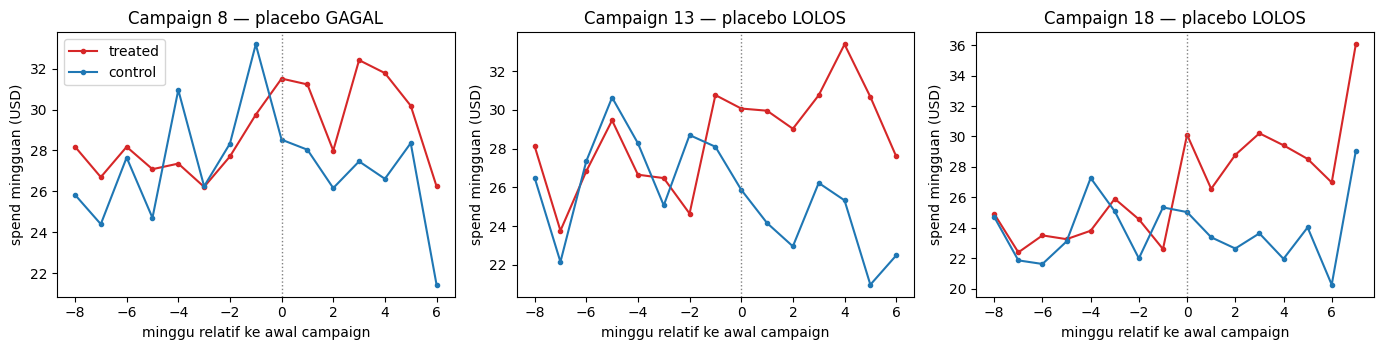

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, cid in zip(axes, (8, 13, 18)):
    sub = events[events["campaign_id"] == cid]
    for grp, color in (("treated", "#d62728"), ("control", "#1f77b4")):
        g = sub[sub["group"] == grp]
        ax.plot(g["event_week"], g["mean_weekly_spend"], "-o", ms=3, color=color, label=grp)
    ax.axvline(0, color="gray", ls=":", lw=1)
    ok = bool(est.loc[est["campaign_id"] == cid, "pre_trend_ok"].iloc[0])
    ax.set(title=f"Campaign {cid} — placebo {'LOLOS' if ok else 'GAGAL'}", xlabel="minggu relatif ke awal campaign", ylabel="spend mingguan (USD)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 4. Hasil per campaign — lift spend mingguan

Forest plot lift % dengan 95% CI bootstrap (1.000 resample per household). Tanda ★ = lolos semua gate (17 campaign). Dari backbone hanya 13 (+22,9% [15,9–30,5]) dan 18 (+24,4% [16,7–32,6]) yang lolos; 8 tampil tanpa ★ karena flag pre-trend. Angka menengah kini layak dibaca — CI-nya lebar, itu keterbatasan ukuran, bukan kegagalan desain.

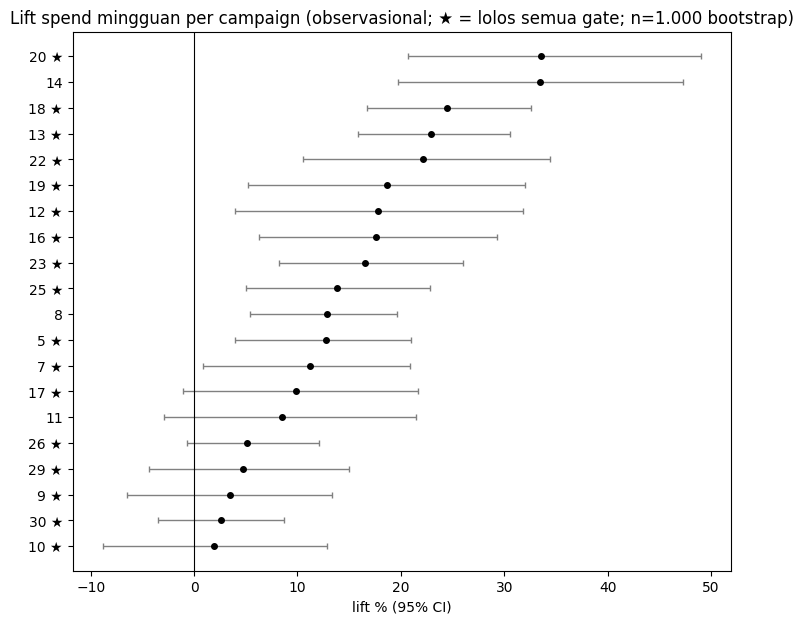

In [5]:
plot = est.sort_values("lift_pct")
star = plot["reliability_flag"].str.startswith("layak")
fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(plot))
ax.errorbar(plot["lift_pct"], y, xerr=[plot["lift_pct"] - plot["lift_ci_low"], plot["lift_ci_high"] - plot["lift_pct"]],
            fmt="o", ms=4, color="black", ecolor="gray", elinewidth=1, capsize=2)
ax.set_yticks(y)
ax.set_yticklabels([f"{int(c)}{' ★' if s else ''}" for c, s in zip(plot["campaign_id"], star)])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Lift spend mingguan per campaign (observasional; ★ = lolos semua gate; n=1.000 bootstrap)",
       xlabel="lift % (95% CI)")
plt.show()

## 5. Ekonomi voucher — dua batas, bukan satu angka

Biaya voucher dihitung dua cara. **Atribusi ketat**: nilai |COUPON_DISC| pada produk yang ada di daftar kupon campaign itu sendiri (masih proxy — keanggotaan daftar produk, bukan identitas kupon). **Batas konservatif**: seluruh kupon yang diredeemasi member treated selama window, termasuk kupon campaign lain yang kebetulan bersamaan — untuk campaign menengah ini mendominasi (93–99% dari total), menandakan window mereka menangkap promo TypeA besar di sekitarnya.

Dengan atribusi ketat, backbone menghasilkan **$3,4–$5,0 spend incremental per $1 voucher** — break-even margin 20–29%, masuk rentang margin grocery. Dengan batas konservatif, rasio jatuh ke $1,3–$2,1 dan margin incremental negatif. Kebenarannya di antara keduanya, dan jarak itulah yang jujur dilaporkan.

In [6]:
eco_cols = ["campaign_id", "n_treated", "redemption_rate",
            "voucher_cost_campaign_items", "inc_spend_per_dollar", "margin25_per_dollar", "margin35_per_dollar",
            "voucher_cost_all_coupons", "inc_spend_per_dollar_allcoupons", "margin35_per_dollar_allcoupons"]
eco = est[est["campaign_id"].isin((8, 13, 18))][eco_cols].copy()
eco["break_even_margin"] = 1 / eco["inc_spend_per_dollar"]
display(eco.round(3))
print("break-even margin = 1 / (incremental spend per $1, atribusi ketat)")

,campaign_id,n_treated,redemption_rate,voucher_cost_campaign_items,inc_spend_per_dollar,margin25_per_dollar,margin35_per_dollar,voucher_cost_all_coupons,inc_spend_per_dollar_allcoupons,margin35_per_dollar_allcoupons,break_even_margin
7,8,1076,0.147,808.70,4.736,0.184,0.658,2843.16,1.347,-0.529,0.211
12,13,1077,0.182,1340.01,4.993,0.248,0.748,3209.40,2.085,-0.270,0.200
17,18,1133,0.189,1925.81,3.433,-0.142,0.202,3635.89,1.818,-0.364,0.291


break-even margin = 1 / (incremental spend per $1, atribusi ketat)


## 6. Artefak & angka kunci

In [7]:
display(pd.DataFrame(
    [(a, f"{(PROCESSED_DIR / a).stat().st_size / 1e6:.1f} MB") for a in ("campaign_did_results.parquet", "campaign_event_study.parquet")],
    columns=["artefak (data/processed/)", "ukuran"],
))
layak = results[results["reliability_flag"].str.startswith("layak")]
print(f"lolos semua gate: {len(layak)} campaign {sorted(layak['campaign_id'].tolist())}")
print(f"pre-trend gagal (flagged): {sorted(est.loc[~est['pre_trend_ok'], 'campaign_id'].tolist())}")
print(results["reliability_flag"].value_counts().to_string())

,artefak (data/processed/),ukuran
0,campaign_did_results.parquet,0.0 MB
1,campaign_event_study.parquet,0.0 MB


lolos semua gate: 17 campaign [5, 7, 9, 10, 12, 13, 16, 17, 18, 19, 20, 22, 23, 25, 26, 29, 30]
pre-trend gagal (flagged): [8, 11, 14]
reliability_flag
layak (observasional)            15
tidak reliable                    9
tidak reliable — pre-trend        3
layak — utama (observasional)     2
excluded                          1


## Catatan kualitas & batasan

- **Semua estimasi observasional** — valid di bawah asumsi unconfoundedness; propensity, balance, dan placebo mengurangi risikonya, bukan menghapus.
- **Campaign 8 gagal placebo** meski estimasinya signifikan (+12,9%) — ditandai `tidak reliable — pre-trend`; signifikansi statistik dan reliabilitas desain adalah dua hal berbeda dan keduanya dilaporkan.
- Estimand overlap weights = efek pada **populasi overlap** (member di margin targeting), bukan ATT pada seluruh treated; untuk keputusan perluasan target justru itu estimand yang relevan. Estimasi ATT-IPW (dengan trim 10–58% sampel) tersedia sebagai kolom sensitivity dan sepakat arah dengan backbone.
- Biaya voucher dua tingkat: atribusi ketat (produk dalam daftar kupon campaign — masih proxy) dan batas konservatif (semua kupon). Angka ekonomi yang benar berada di antara keduanya.
- CI bootstrap memegang bobot propensity tetap; diagnostik refit-propensity pada campaign 18 menghasilkan CI yang praktis identik ([4,13; 7,67] vs [3,93; 7,67]) — bobot overlap yang terbatas membuat ketidakpastian propensity kecil.
- Semua nominal USD historis; bukan klaim kausal; margin tetap parameter (15/25/35%), bukan data.